In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
customers = pd.read_csv(r"D:\projects\RetailIQ\archive\customers.csv")
products = pd.read_csv(r"D:\projects\RetailIQ\archive\products.csv")
sales = pd.read_csv(r"D:\projects\RetailIQ\archive\sales.csv")
print("Customers:",customers.shape)
print("Products:",products.shape)
print("Sales:",sales.shape)


Customers: (40000, 15)
Products: (2000, 12)
Sales: (250000, 21)


In [4]:
pd.set_option('display.expand_frame_repr', False)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 2000)

In [5]:
print(customers.head(5))
print("="*200)
print("="*200)
print(products.head(5))
print("="*200)
print("="*200)
print(sales.head(5))

    Customer_ID  Customer_Name  Gender  Age Age_Group Date_of_Birth                     Email           Phone      City        State  Pincode Registration_Date Customer_Tier  Total_Orders  Total_Spent
0  CUST00000001  Akash Agarwal    male   48     46-55    1977-01-13    akashagarwal@gmail.com  +91-9625152011   Patiala       Punjab   122521        2024-01-28          Gold             5     40098.48
1  CUST00000002  Farhan Rahman    male   73       65+    1952-01-20    farhanrahman@gmail.com  +91-8593009465  Durgapur  West Bengal   226518        2023-08-25      Platinum             8     63676.24
2  CUST00000003   Suresh Kumar    male   31     26-35    1994-01-09  sureshkumar755@gmail.com  +91-7935884774  Gurugram      Haryana   520400        2023-08-30        Silver             0         0.00
3  CUST00000004  Aditya Pandey    male   41     36-45    1984-01-12  adityapandey@outlook.com  +91-9015046072   Kolkata  West Bengal   735356        2024-03-11      Platinum             5    28832

In [6]:
datasets = {
    "Customers": customers,
    "Products": products,
    "Sales": sales
}

for name, df in datasets.items():
    print(f"\n{'=' * 40}")
    print(f"{name.upper()} DATASET")
    print(f"{'=' * 40}")
    print("Shape:", df.shape)
    print("Duplicate rows:", df.duplicated().sum())
    print("\nData types:")
    print(df.dtypes)


CUSTOMERS DATASET
Shape: (40000, 15)
Duplicate rows: 0

Data types:
Customer_ID              str
Customer_Name            str
Gender                   str
Age                    int64
Age_Group                str
Date_of_Birth            str
Email                    str
Phone                    str
City                     str
State                    str
Pincode                int64
Registration_Date        str
Customer_Tier            str
Total_Orders           int64
Total_Spent          float64
dtype: object

PRODUCTS DATASET
Shape: (2000, 12)
Duplicate rows: 0

Data types:
Product_ID              str
Product_Name            str
Category                str
Brand                   str
Original_Price      float64
Discount_Percent      int64
Discount_Amount     float64
Selling_Price       float64
Stock_Quantity        int64
Weight_kg           float64
Avg_Rating          float64
Total_Reviews         int64
dtype: object

SALES DATASET
Shape: (250000, 21)
Duplicate rows: 0

Data types:

In [7]:
print(f"Sales :\n{sales.isnull().sum()}")
print(f"\nCustomer :\n{customers.isnull().sum()}")
print(f"\nProducts :\n{products.isnull().sum()}")


Sales :
Order_ID                   0
Customer_ID                0
Product_ID                 0
Order_Date                 0
Order_Time                 0
Delivery_Date              0
Quantity                   0
Unit_Price                 0
Order_Value                0
Shipping_Cost              0
Coupon_Code           199815
Coupon_Discount            0
Total_Amount               0
Payment_Mode               0
Order_Status               0
Rating                129970
Review_Text           129970
City                       0
State                      0
Customer_Age               0
Customer_Age_Group         0
dtype: int64

Customer :
Customer_ID          0
Customer_Name        0
Gender               0
Age                  0
Age_Group            0
Date_of_Birth        0
Email                0
Phone                0
City                 0
State                0
Pincode              0
Registration_Date    0
Customer_Tier        0
Total_Orders         0
Total_Spent          0
dtype: int64


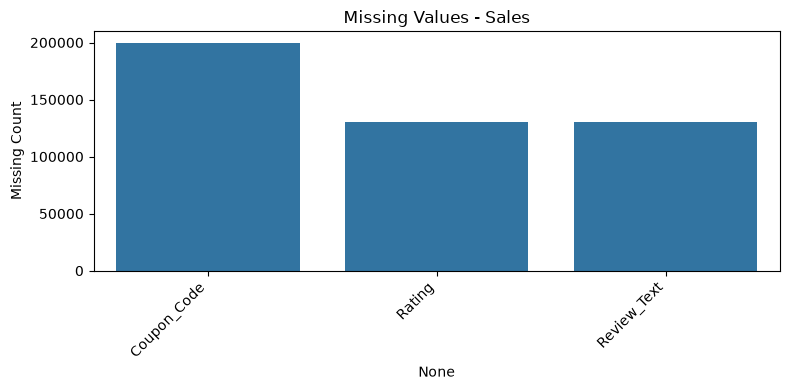

In [8]:
for name, df in datasets.items():
    missing = df.isnull().sum()
    missing = missing[missing > 0]

    if not missing.empty:
        plt.figure(figsize=(8, 4))
        sns.barplot(x=missing.index, y=missing.values)
        plt.title(f"Missing Values - {name}")
        plt.xticks(rotation=45, ha="right")
        plt.ylabel("Missing Count")
        plt.tight_layout()
        plt.show()

In [9]:
# Check customer IDs
missing_customers = ~sales["Customer_ID"].isin(customers["Customer_ID"])

print("Sales records with unknown customers:",
      missing_customers.sum())

# Check product IDs
missing_products = ~sales["Product_ID"].isin(products["Product_ID"])

print("Sales records with unknown products:",
      missing_products.sum())

Sales records with unknown customers: 0
Sales records with unknown products: 0


In [10]:
# Convert date columns to datetime
sales["Order_Date"] = pd.to_datetime(
    sales["Order_Date"], errors="coerce"
)

sales["Delivery_Date"] = pd.to_datetime(
    sales["Delivery_Date"], errors="coerce"
)

customers["Registration_Date"] = pd.to_datetime(
    customers["Registration_Date"], errors="coerce"
)

# Check invalid dates
print("Invalid order dates:", sales["Order_Date"].isna().sum())
print("Invalid delivery dates:", sales["Delivery_Date"].isna().sum())
print("Invalid registration dates:", customers["Registration_Date"].isna().sum())

# Check suspicious numeric values
print("\nNegative quantities:", (sales["Quantity"] < 0).sum())
print("Negative unit prices:", (sales["Unit_Price"] < 0).sum())
print("Negative total amounts:", (sales["Total_Amount"] < 0).sum())

Invalid order dates: 0
Invalid delivery dates: 0
Invalid registration dates: 0

Negative quantities: 0
Negative unit prices: 0
Negative total amounts: 5


In [11]:
sales.loc[
    sales["Total_Amount"] < 0, 
    ["Order_ID", "Quantity", "Unit_Price", "Order_Value", "Shipping_Cost", "Coupon_Discount","Total_Amount","Order_Status"]]

,Order_ID,Quantity,Unit_Price,Order_Value,Shipping_Cost,Coupon_Discount,Total_Amount,Order_Status
84204,ORD0000084205,1,35.57,35.57,62.36,100.0,-2.07,Delivered
182883,ORD0000182884,1,26.13,26.13,52.31,100.0,-21.56,Delivered
207695,ORD0000207696,1,26.13,26.13,62.56,100.0,-11.31,Delivered
216234,ORD0000216235,1,26.13,26.13,57.40,100.0,-16.47,Delivered
249820,ORD0000249821,1,35.57,35.57,52.45,100.0,-11.98,Cancelled


In [12]:
sales.loc[
    sales["Total_Amount"] < 0,
    [
        "Order_ID",
        "Quantity",
        "Unit_Price",
        "Order_Value",
        "Shipping_Cost",
        "Coupon_Discount",
        "Total_Amount",
        "Order_Status"
    ]
].assign(
    Expected_Total=lambda df:
        df["Order_Value"] + df["Shipping_Cost"] - df["Coupon_Discount"]
)

,Order_ID,Quantity,Unit_Price,Order_Value,Shipping_Cost,Coupon_Discount,Total_Amount,Order_Status,Expected_Total
84204,ORD0000084205,1,35.57,35.57,62.36,100.0,-2.07,Delivered,-2.07
182883,ORD0000182884,1,26.13,26.13,52.31,100.0,-21.56,Delivered,-21.56
207695,ORD0000207696,1,26.13,26.13,62.56,100.0,-11.31,Delivered,-11.31
216234,ORD0000216235,1,26.13,26.13,57.40,100.0,-16.47,Delivered,-16.47
249820,ORD0000249821,1,35.57,35.57,52.45,100.0,-11.98,Cancelled,-11.98


In [13]:
sales["Order_Status"].value_counts()

Order_Status
Delivered     200139
Cancelled      12507
Returned       12493
Shipped        12459
Processing     12402
Name: count, dtype: int64

In [14]:
print("First order date:", sales["Order_Date"].min())
print("Last order date:", sales["Order_Date"].max())

First order date: 2024-06-01 00:00:00
Last order date: 2026-06-30 00:00:00


In [15]:
sales["Calculated_Order_Value"] = (
    sales["Quantity"] * sales["Unit_Price"]
)

mismatch = (
    (sales["Order_Value"] - sales["Calculated_Order_Value"]).abs()
    > 0.01
)

print("Order value mismatches:", mismatch.sum())

Order value mismatches: 0


In [16]:
print("Duplicate Customer IDs:", customers["Customer_ID"].duplicated().sum())
print("Duplicate Product IDs:", products["Product_ID"].duplicated().sum())
print("Duplicate Order IDs:", sales["Order_ID"].duplicated().sum())

Duplicate Customer IDs: 0
Duplicate Product IDs: 0
Duplicate Order IDs: 0


In [17]:
products["Calculated_Price"] = (
    products["Original_Price"]
     - products["Discount_Amount"] 
).round(2)

mismatch = (
    (products["Selling_Price"] - products["Calculated_Price"]).abs()
    > 0.01
)

print("Selling price mismatches:", mismatch.sum())

Selling price mismatches: 0


In [18]:
print("Non-positive original prices:",
      (products["Original_Price"] <= 0).sum())

print("Negative discount amounts:",
      (products["Discount_Amount"] < 0).sum())

print("Negative stock quantities:",
      (products["Stock_Quantity"] < 0).sum())

print("Invalid discount percentages:",
      ((products["Discount_Percent"] < 0) |
       (products["Discount_Percent"] > 100)).sum())

Non-positive original prices: 0
Negative discount amounts: 0
Negative stock quantities: 0
Invalid discount percentages: 0


In [19]:
print("Invalid ages:", 
      ((customers["Age"] < 0) | (customers["Age"] > 120)).sum())

print("Invalid total orders:", 
      (customers["Total_Orders"] < 0).sum())

print("Invalid total spent:", 
      (customers["Total_Spent"] < 0).sum())

print("Duplicate customer emails:", 
      customers["Email"].duplicated().sum())

Invalid ages: 0
Invalid total orders: 0
Invalid total spent: 0
Duplicate customer emails: 13433


In [20]:
duplicate_emails = customers[
    customers["Email"].duplicated(keep=False)
].sort_values("Email")

duplicate_emails[["Customer_ID", "Customer_Name", "Email"]].head(20)

,Customer_ID,Customer_Name,Email
28381,CUST00028382,Aadhya Agarwal,aadhyaagarwal302@outlook.com
38942,CUST00038943,Aadhya Agarwal,aadhyaagarwal302@outlook.com
4053,CUST00004054,Aadhya Agarwal,aadhyaagarwal@gmail.com
7529,CUST00007530,Aadhya Agarwal,aadhyaagarwal@gmail.com
10993,CUST00010994,Aadhya Agarwal,aadhyaagarwal@gmail.com
17544,CUST00017545,Aadhya Agarwal,aadhyaagarwal@gmail.com
18291,CUST00018292,Aadhya Agarwal,aadhyaagarwal@gmail.com
24963,CUST00024964,Aadhya Agarwal,aadhyaagarwal@gmail.com
25247,CUST00025248,Aadhya Agarwal,aadhyaagarwal@gmail.com
30287,CUST00030288,Aadhya Agarwal,aadhyaagarwal@gmail.com


In [21]:
print("Total customer records:", len(customers))
print("Unique customer IDs:", customers["Customer_ID"].nunique())
print("Unique email addresses:", customers["Email"].nunique())
print("Unique customer names:", customers["Customer_Name"].nunique())

Total customer records: 40000
Unique customer IDs: 40000
Unique email addresses: 26567
Unique customer names: 927


In [22]:
print("Total Orders:", sales["Order_ID"].nunique())
print("Total Sales Records:", len(sales))
print("\nOrder Status:")
print(sales["Order_Status"].value_counts())

Total Orders: 250000
Total Sales Records: 250000

Order Status:
Order_Status
Delivered     200139
Cancelled      12507
Returned       12493
Shipped        12459
Processing     12402
Name: count, dtype: int64


In [23]:
status_percent = (
    sales["Order_Status"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print(status_percent)

Order_Status
Delivered     80.06
Cancelled      5.00
Returned       5.00
Shipped        4.98
Processing     4.96
Name: proportion, dtype: float64


In [24]:
revenue_by_status = sales.groupby("Order_Status")["Total_Amount"].sum()

print(revenue_by_status.round(2))

Order_Status
Cancelled     3.021405e+08
Delivered     4.741566e+09
Processing    2.954608e+08
Returned      3.004047e+08
Shipped       2.911208e+08
Name: Total_Amount, dtype: float64


In [25]:
delivered_sales = sales[sales["Order_Status"] == "Delivered"]

total_revenue = delivered_sales["Total_Amount"].sum()
average_order_value = delivered_sales["Total_Amount"].mean()

print(f"Delivered Revenue: ₹{total_revenue:,.2f}")
print(f"Average Delivered Order Value: ₹{average_order_value:,.2f}")
print(f"Number of Delivered Orders: {delivered_sales['Order_ID'].nunique():,}")

Delivered Revenue: ₹4,741,566,354.41
Average Delivered Order Value: ₹23,691.37
Number of Delivered Orders: 200,139


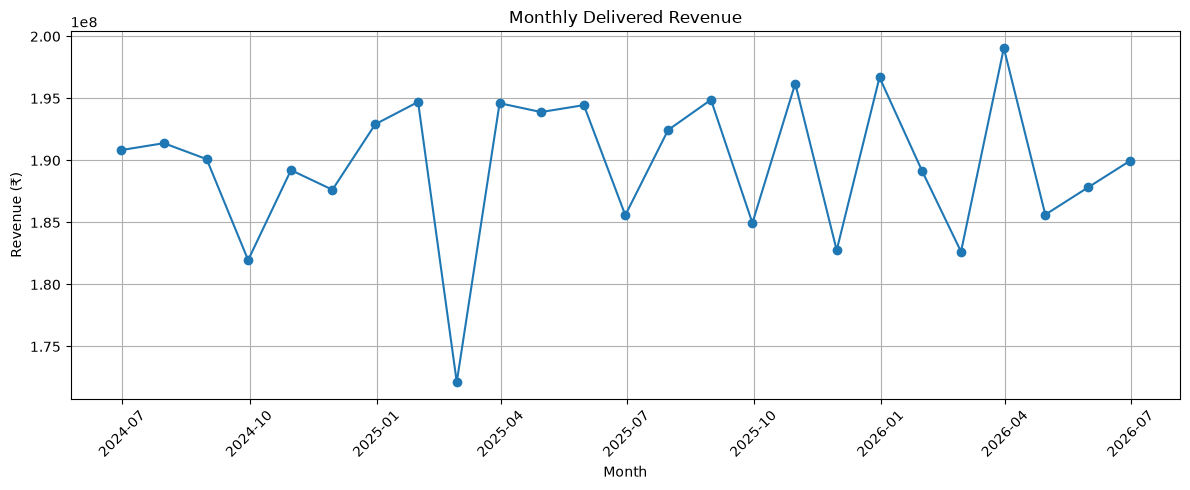

In [26]:
monthly_sales = (
    delivered_sales
    .set_index("Order_Date")
    .resample("ME")["Total_Amount"]
    .sum()
)

plt.figure(figsize=(12, 5))
plt.plot(monthly_sales.index, monthly_sales.values, marker="o")
plt.title("Monthly Delivered Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue (₹)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

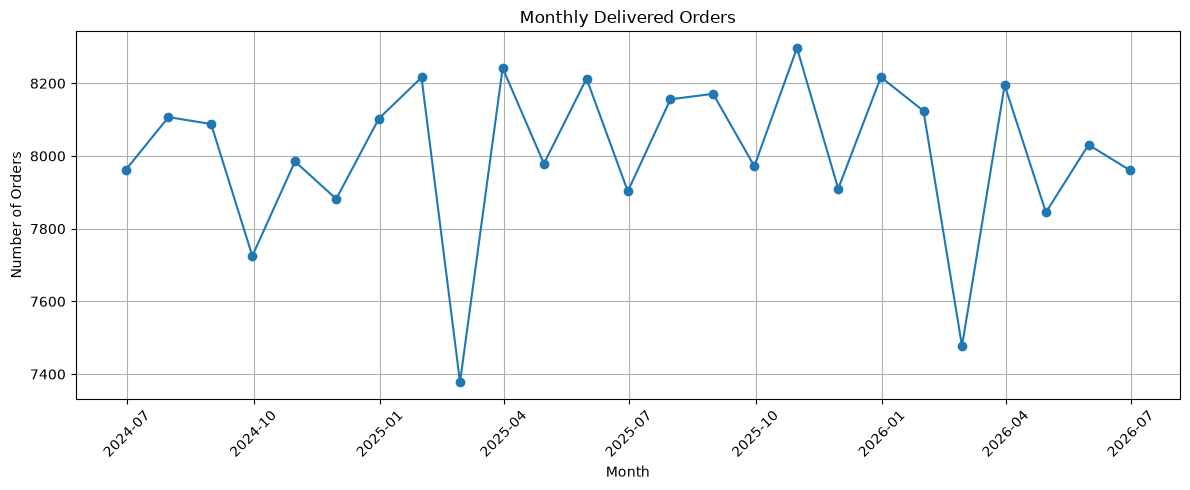

In [27]:
monthly_orders = (
    delivered_sales
    .set_index("Order_Date")
    .resample("ME")["Order_ID"]
    .nunique()
)

plt.figure(figsize=(12, 5))
plt.plot(monthly_orders.index, monthly_orders.values, marker="o")
plt.title("Monthly Delivered Orders")
plt.xlabel("Month")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [28]:
monthly_summary = pd.DataFrame({
    "Delivered_Orders": monthly_orders,
    "Delivered_Revenue": monthly_sales
})

monthly_summary["Average_Order_Value"] = (
    monthly_summary["Delivered_Revenue"] /
    monthly_summary["Delivered_Orders"]
)

display(monthly_summary.round(2))

,Delivered_Orders,Delivered_Revenue,Average_Order_Value
Order_Date,,,
2024-06-30,7962,1.908292e+08,23967.49
2024-07-31,8107,1.913867e+08,23607.59
2024-08-31,8088,1.900993e+08,23503.86
2024-09-30,7725,1.819649e+08,23555.32
2024-10-31,7985,1.892169e+08,23696.54
2024-11-30,7882,1.876325e+08,23805.19
2024-12-31,8103,1.929125e+08,23807.54
2025-01-31,8216,1.947113e+08,23699.04
2025-02-28,7378,1.721274e+08,23329.82


In [29]:
monthly_summary["Revenue_Growth_%"] = (
    monthly_summary["Delivered_Revenue"]
    .pct_change()
    .mul(100)
)

display(monthly_summary.round(2))


,Delivered_Orders,Delivered_Revenue,Average_Order_Value,Revenue_Growth_%
Order_Date,,,,
2024-06-30,7962,1.908292e+08,23967.49,NaN
2024-07-31,8107,1.913867e+08,23607.59,0.29
2024-08-31,8088,1.900993e+08,23503.86,-0.67
2024-09-30,7725,1.819649e+08,23555.32,-4.28
2024-10-31,7985,1.892169e+08,23696.54,3.99
2024-11-30,7882,1.876325e+08,23805.19,-0.84
2024-12-31,8103,1.929125e+08,23807.54,2.81
2025-01-31,8216,1.947113e+08,23699.04,0.93
2025-02-28,7378,1.721274e+08,23329.82,-11.60


Category
Electronics    3.443288e+09
Home           5.732860e+08
Sports         3.793918e+08
Fashion        2.665794e+08
Grocery        3.345878e+07
Beauty         3.065905e+07
Books          1.490332e+07
Name: Total_Amount, dtype: float64


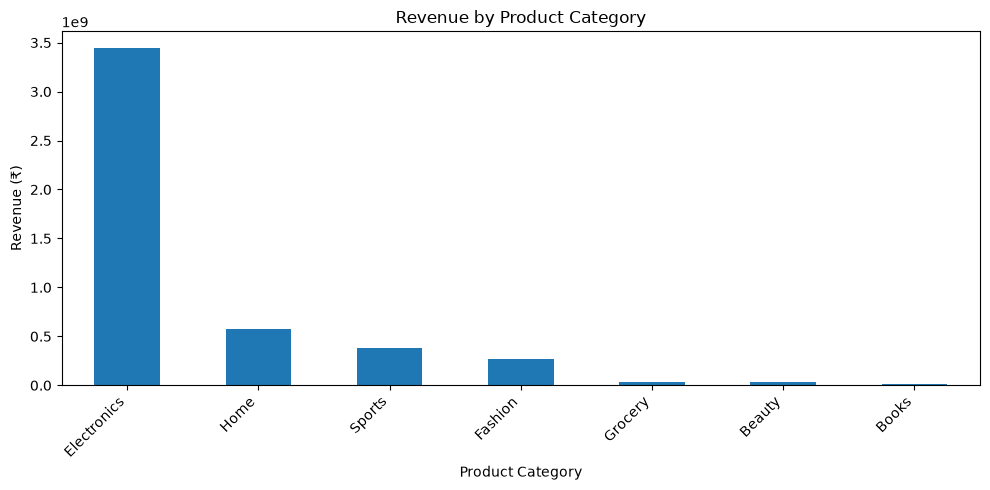

In [30]:
# Combine sales records with product categories
sales_products = delivered_sales.merge(
    products[["Product_ID", "Category"]],
    on="Product_ID",
    how="left"
)

# Calculate revenue for each category
category_revenue = (
    sales_products.groupby("Category")["Total_Amount"]
    .sum()
    .sort_values(ascending=False)
)

print(category_revenue.round(2))

# Visualize category revenue
plt.figure(figsize=(10, 5))
category_revenue.plot(kind="bar")
plt.title("Revenue by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Revenue (₹)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [31]:
# Merge delivered sales with product names
sales_products = delivered_sales.merge(
    products[["Product_ID", "Product_Name", "Category"]],
    on="Product_ID",
    how="left"
)

# Find the top 10 products by revenue
top_products = (
    sales_products.groupby("Product_Name")
    .agg(
        Revenue=("Total_Amount", "sum"),
        Units_Sold=("Quantity", "sum")
    )
    .sort_values("Revenue", ascending=False)
    .head(10)
)

display(top_products.round(2))

,Revenue,Units_Sold
Product_Name,,
Noise Watch V1,1.548714e+08,1843
Samsung Mobile V4,1.414145e+08,2281
HP Laptop V5,1.290403e+08,2081
boAt Headphones V8,1.281176e+08,2167
Noise Watch V7,1.144468e+08,2120
boAt Headphones V6,1.114845e+08,2754
Apple iPhone V7,1.090991e+08,2100
HP Laptop V10,1.061172e+08,2252
HP Laptop V4,1.004519e+08,1450


In [32]:
payment_analysis = (
    delivered_sales.groupby("Payment_Mode")
    .agg(
        Orders=("Order_ID", "nunique"),
        Revenue=("Total_Amount", "sum")
    )
    .sort_values("Orders", ascending=False)
)

payment_analysis["Order_Percentage"] = (
    payment_analysis["Orders"] /
    payment_analysis["Orders"].sum() * 100
).round(2)

display(payment_analysis.round(2))

,Orders,Revenue,Order_Percentage
Payment_Mode,,,
UPI,102846,2.539152e+09,51.39
COD,65679,1.475101e+09,32.82
Debit Card,23124,5.036725e+08,11.55
Credit Card,8490,2.236412e+08,4.24


In [33]:
customer_analysis = (
    customers.groupby("Customer_Tier")
    .agg(
        Customers=("Customer_ID", "nunique"),
        Total_Spent=("Total_Spent", "sum"),
        Average_Spent=("Total_Spent", "mean")
    )
    .sort_values("Total_Spent", ascending=False)
)

display(customer_analysis.round(2))

,Customers,Total_Spent,Average_Spent
Customer_Tier,,,
Platinum,27349,4.455365e+09,162907.79
Gold,6692,2.324346e+08,34733.20
Silver,5959,5.376676e+07,9022.78


In [34]:
product_performance = (
    products.groupby("Category")
    .agg(
        Products=("Product_ID", "nunique"),
        Average_Rating=("Avg_Rating", "mean"),
        Total_Reviews=("Total_Reviews", "sum"),
        Total_Stock=("Stock_Quantity", "sum")
    )
    .sort_values("Average_Rating", ascending=False)
)

display(product_performance.round(2))

,Products,Average_Rating,Total_Reviews,Total_Stock
Category,,,,
Fashion,285,4.40,23813,137504
Home,285,4.40,16144,141562
Beauty,285,4.40,8076,152559
Grocery,285,4.40,16209,141609
Electronics,290,4.40,32040,150505
Books,285,4.39,9694,141501
Sports,285,4.39,14054,141718


In [35]:
state_sales = (
    delivered_sales.groupby("State")
    .agg(
        Orders=("Order_ID", "nunique"),
        Revenue=("Total_Amount", "sum")
    )
    .sort_values("Revenue", ascending=False)
)

state_sales["Revenue_Percentage"] = (
    state_sales["Revenue"] / state_sales["Revenue"].sum() * 100
).round(2)

display(state_sales.head(10).round(2))

,Orders,Revenue,Revenue_Percentage
State,,,
UP,26134,6.187059e+08,13.05
Rajasthan,25440,6.047446e+08,12.75
Haryana,25656,5.977207e+08,12.61
Maharashtra,20364,4.847609e+08,10.22
Punjab,20240,4.768408e+08,10.06
Gujarat,20141,4.760159e+08,10.04
Delhi,15614,3.816592e+08,8.05
Tamil Nadu,15804,3.759771e+08,7.93
West Bengal,15514,3.647380e+08,7.69


In [36]:
eda_summary = {
    "Total_Customers": customers["Customer_ID"].nunique(),
    "Total_Products": products["Product_ID"].nunique(),
    "Total_Orders": sales["Order_ID"].nunique(),
    "Delivered_Orders": delivered_sales["Order_ID"].nunique(),
    "Delivered_Revenue": delivered_sales["Total_Amount"].sum(),
    "Average_Delivered_Order_Value": delivered_sales["Total_Amount"].mean(),
    "Top_Category": category_revenue.idxmax(),
    "Top_Product": top_products["Revenue"].idxmax(),
    "Top_Payment_Method": payment_analysis["Orders"].idxmax(),
    "Top_State": state_sales["Revenue"].idxmax()
}

for metric, value in eda_summary.items():
    print(f"{metric}: {value}")

Total_Customers: 40000
Total_Products: 2000
Total_Orders: 250000
Delivered_Orders: 200139
Delivered_Revenue: 4741566354.41
Average_Delivered_Order_Value: 23691.366272490617
Top_Category: Electronics
Top_Product: Noise Watch V1
Top_Payment_Method: UPI
Top_State: UP


In [38]:
from pathlib import Path

# Create a folder for processed datasets
processed_dir = Path("../data_processed")
processed_dir.mkdir(parents=True, exist_ok=True)

# Save the processed datasets
customers.to_csv(processed_dir / "customers_processed.csv", index=False)
products.to_csv(processed_dir / "products_processed.csv", index=False)
sales.to_csv(processed_dir / "sales_processed.csv", index=False)

print("Processed datasets saved successfully!")

Processed datasets saved successfully!
